# mmb0-1b_smb1-1b_2p

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 21.10.2024
- Date of Last Modification: 21.10.2024 (by Sebastian Birk; sb75@sanger.ac.uk)

# 1. Setup

## 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import logging
import os
import pickle
import random
from datetime import datetime

import anndata as ad
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
import seaborn as sns
import squidpy as sq
from sklearn.model_selection import train_test_split

from nichejepa.datasets import prepare_dataset
from nichejepa.infer import infer
from nichejepa.train import train
from nichejepa.utils.config import create_params_from_YAML_wandb_config
from nichejepa.utils.distributed import init_distributed
from nichejepa.utils.evaluation import clustering_metrics, classification_metrics

from analysis_utils import *

## 1.2 Load Config/Params
All setup will be done in the config file. Please edit that file to continue.

In [4]:
# Set inference params
load_timestamp = None # '27092024_185200_331', None
read_checkpoint = None # 'jepa-ep5.pth.tar', None
exclude_unshared_tokens = False # True, False
agg_type = 'cls' # 'avg', 'weighted_avg', 'cls'

In [5]:
model_config_folder_path = '../../config/model'
artifacts_folder_path = '../../artifacts'

In [6]:
# Set up logger
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

# Load config
if not load_timestamp:
    params = create_params_from_YAML_wandb_config(f'{model_config_folder_path}/mmb0-1b_smb1-1b_2p.yaml',logger)
else:
    params = create_params_from_YAML_wandb_config(f'{artifacts_folder_path}/mmb0-1b_smb1-1b_2p/{load_timestamp}/params.yaml',logger)

if read_checkpoint:
    params['meta']['read_checkpoint'] = read_checkpoint

params

INFO:root:Loaded parameters from YAML file.


{'data': {'dataset_name': 'mmb0-1b_smb1-1b_2p',
  'raw_data_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/silver/mmb0-1b_smb1-1b_2p_labels',
  'tokenized_data_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/gold/cell-neighborhood-tokenizer/mmb0-1b_smb1-1b_2p/mmb0-1b_smb1-1b_2p_read_depth_shifted_log_2170.dataset',
  'tokenizer_type': 'cell_neighborhood',
  'random_state': 0,
  'sample_subset': False,
  'split': 0.2,
  'stratify': False,
  'vocab_size': 1686,
  'seq_len_cell': 349,
  'seq_len_neighborhood': 756,
  'n_segments': 2,
  'sampling_strategy': None,
  'batch_size': 64,
  'num_workers': 6,
  'pin_memory': True,
  'separate_cls': True},
 'meta': {'gt_type': 'rank',
  'enc_depth': 3,
  'enc_emb_dim': 768,
  'pred_depth': 1,
  'pred_emb_dim': 768,
  'special_tokens': ['cls_cell', 'cls_neighborhood', 'batch'],
  'pos_learnable': False,
  'seg_learnable': False,
  'use_bfloat16': True},
 'mask': {'n_contexts': 1,
  'n_targets': 5,
  'block_masking': True,
  '

In [7]:
if not load_timestamp:
    current_timestamp = (
        datetime.now().strftime("%d%m%Y_%H%M%S") +
        f"_{datetime.now().microsecond // 1000:03d}")
    folder_path = os.path.join(artifacts_folder_path,
                               params['data']['dataset_name'],
                               current_timestamp)
else:
    folder_path = f'{artifacts_folder_path}/mmb0-1b_smb1-1b_2p/{load_timestamp}'
    
folder_path

'../../artifacts/mmb0-1b_smb1-1b_2p/25102024_114401_334'

## 1.3 Create Train & Test Dataset

In [8]:
train_dataset, test_dataset = prepare_dataset(params)
train_dataset

Dataset({
    features: ['cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value_token', 'gene_panel_value_token', 'assay_value_token', 'species_value_token', 'tissue_value_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens', 'seg_tokens', 'cls_cell_token', 'cls_neighborhood_token'],
    num_rows: 74016
})

## 1.4 Run INIT Distributed

In [9]:
devices=['cuda:0']
world_size=1
os.environ['CUDA_VISIBLE_DEVICES'] = str(devices[rank].split(':')[-1])

logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

world_size, rank = init_distributed(rank_and_world_size=(rank, world_size), port=random.randint(40000, 50000))
logger.info(f'Running... (rank: {rank}/{world_size})')

INFO:torch.distributed.distributed_c10d:Added key: store_based_barrier_key:1 to store for rank: 0
INFO:torch.distributed.distributed_c10d:Rank 0: Completed store-based barrier for key:store_based_barrier_key:1 with 1 nodes.
INFO:root:Running... (rank: 0/1)


# 2. Model Training

In [10]:
### Train model
train(params,
      train_dataset,
      test_dataset,
      save_folder_path=folder_path)

INFO:root:Initialized (rank/world-size) 0/1.
INFO:root:GeneTransformerRankEncoder(
  (token_embed): Embedding(1686, 768, padding_idx=0)
  (seg_embed): Embedding(13, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (p

# 3. Analysis

## 3.1 Run Model Inference

In [11]:
# Get gene tokens that overlap between gene panels to obtain excluded tokens from aggregation
if exclude_unshared_tokens:
    gene_panel_gene_mapping_file_path = '/lustre/scratch126/cellgen/team361/am84/NicheJEPA/datasets/am84/tokenizer/cell-neighborhood-tokenizer/merfish_mouse_brain_8-batch_2-gene-panels/gene_panel_ID_to_gene_panel_dict.pkl'
    token_dictionary_file_path = '/lustre/scratch126/cellgen/team361/am84/NicheJEPA/datasets/am84/tokenizer/cell-neighborhood-tokenizer/merfish_mouse_brain_8-batch_2-gene-panels/token_dictionary_no_cls_no_sep.pkl'
    
    with open(gene_panel_gene_mapping_file_path, 'rb') as file:
        gene_panel_gene_mapping = pickle.load(file)
    
    with open(token_dictionary_file_path, 'rb') as file:
        token_dictionary = pickle.load(file)
    
    genes_panel0 = set(gene_panel_gene_mapping[0])
    genes_panel1 = set(gene_panel_gene_mapping[1])
    
    overlapping_genes = list(genes_panel0.intersection(genes_panel1))
    
    overlapping_gene_tokens = [token_dictionary[gene] for gene in overlapping_genes if gene in token_dictionary]
    
    excluded_tokens = list(set(token_dictionary.values()) - set(overlapping_gene_tokens))

In [ ]:
folder_path = '../../artifacts/mmb0-1b_smb1-1b_2p/24102024_155256_488'
params['state']['read_checkpoint'] = 'nichejepa-ep50.pth.tar'

In [24]:
folder_path

'../../artifacts/mmb0-1b_smb1-1b_2p/25102024_114401_334'

In [12]:
masked_tokens = [199,
 558,
 1145,
 811,
 575,
 895,
 1068,
 46,
 902,
 1638,
 1497,
 715,
 1583,
 1126,
 996,
 1224,
 672,
 1494,
 654,
 414,
 359,
 182,
 1290,
 1527,
 1241,
 1158,
 1054,
 559,
 733,
 822,
 236,
 1069,
 1579,
 341,
 739,
 1035,
 1084,
 949,
 398,
 443,
 151,
 817,
 1316,
 271,
 1650,
 1307,
 995,
 1281,
 656,
 1106,
 113,
 314,
 84,
 497,
 1221,
 885,
 587,
 1389,
 1027,
 1657,
 223,
 1550,
 673,
 1361,
 495,
 831,
 1089,
 1642,
 1663,
 1267,
 528,
 1436,
 207,
 1155,
 1172,
 800,
 418,
 1061,
 1083,
 391,
 866,
 597,
 361,
 156,
 1568,
 658,
 1206,
 1021,
 1383,
 1056,
 1032,
 1624,
 899,
 350,
 409,
 1148,
 425,
 250,
 440,
 1486,
 176,
 150,
 1478,
 97,
 630,
 426,
 637,
 717,
 781,
 973,
 1546,
 1144,
 910,
 148,
 948,
 622,
 872,
 348,
 1524,
 520,
 1232,
 686,
 1523,
 115,
 1600,
 420,
 697,
 29,
 473,
 924,
 869,
 196,
 1398,
 1023,
 519,
 14,
 460,
 881,
 288,
 1581,
 691,
 1427,
 712,
 1587,
 235,
 1212,
 55,
 1417,
 1039,
 1531,
 232,
 651,
 219,
 1672,
 1372,
 1051,
 1142,
 336,
 270,
 280,
 818,
 989,
 922,
 1385,
 1085,
 98,
 1421,
 1554,
 1419,
 1012,
 345,
 729,
 847,
 917,
 486,
 1033,
 966,
 138,
 501,
 347,
 1442,
 724,
 1377,
 333,
 707,
 1302,
 1570,
 1096,
 532,
 985,
 971,
 188,
 1505,
 960,
 1095,
 1137,
 1139,
 1130,
 1567,
 103,
 998,
 1119,
 518,
 919,
 1065,
 259,
 596,
 360,
 925,
 1244,
 842,
 993,
 754,
 1403,
 450,
 1292,
 1140,
 435,
 1174,
 85,
 1596,
 1143,
 768,
 598,
 1670,
 1300,
 1239,
 687,
 1662,
 592,
 703,
 451,
 908,
 681,
 941,
 1260,
 1225,
 252,
 1136,
 588,
 1022,
 583,
 1668,
 51,
 1092,
 1586,
 1602,
 208,
 1036,
 1506,
 870,
 863,
 942,
 670,
 122,
 1288,
 127,
 1289,
 130,
 904,
 1058,
 1637,
 535,
 1665,
 353,
 478,
 780,
 586,
 1057,
 403,
 926,
 1104,
 1386,
 751,
 1582,
 1196,
 363,
 629,
 329,
 1105,
 1356,
 128,
 194,
 81,
 744,
 896,
 1203,
 568,
 538,
 381,
 1440,
 979,
 1572,
 216,
 614,
 544,
 1589,
 47,
 1138,
 1060,
 737,
 104,
 1276,
 911,
 574,
 167,
 585,
 741,
 468,
 704,
 857,
 153,
 1462,
 512,
 569,
 335,
 807,
 694,
 1250,
 1280,
 1479,
 1643,
 1296,
 1162,
 1625,
 507,
 11,
 1368,
 635,
 990,
 1320,
 510,
 1189,
 659,
 999,
 1373,
 456,
 628,
 1049,
 1052,
 503,
 277,
 784,
 416,
 888,
 322,
 380,
 1482,
 89,
 1470,
 330,
 855,
 181,
 964,
 1488,
 551,
 734,
 1278,
 757,
 1273,
 1394,
 494,
 1200,
 790,
 120,
 1416,
 1443,
 481,
 40,
 644,
 1608,
 1659,
 787,
 469,
 474,
 1167,
 310,
 1594,
 77,
 1601,
 487,
 231,
 155,
 805,
 1593,
 981,
 192,
 457,
 1127,
 281,
 412,
 251,
 1028,
 1091,
 1016,
 1375,
 894,
 1334,
 1409,
 808,
 109,
 482,
 699,
 1070,
 1640,
 197,
 230,
 79,
 1223,
 647,
 455,
 1415,
 680,
 1181,
 1535,
 511,
 331,
 526,
 146,
 22,
 1128,
 1518,
 891,
 170,
 158,
 956,
 294,
 770,
 1559,
 874,
 1153,
 1094,
 810,
 1141,
 916,
 273,
 240,
 1020,
 1606,
 1536,
 424,
 175,
 1101,
 1469,
 1522,
 747,
 1585,
 1191,
 396,
 814,
 685,
 1340,
 1029,
 813,
 1066,
 470,
 1496,
 1255,
 1355,
 41,
 834,
 756,
 300,
 893,
 914,
 1114,
 952,
 642,
 683,
 1341,
 1211,
 374,
 1078,
 332,
 664,
 812,
 550,
 1047,
 1393,
 1472,
 934,
 1447,
 595,
 661,
 1467,
 1516,
 112,
 636,
 1610,
 786,
 28,
 861,
 226,
 164,
 897,
 1390,
 1434,
 816,
 846,
 1631,
 983,
 1213,
 1457,
 710,
 1444,
 984,
 436,
 243,
 438,
 1077,
 889,
 1604,
 83,
 210,
 222,
 539,
 1048,
 1075,
 1090,
 157,
 174,
 1263,
 326,
 1645,
 1180,
 1551,
 1072,
 969,
 1002,
 709,
 475,
 1268,
 1195,
 492,
 154,
 1157,
 458,
 1006,
 1318,
 815,
 826,
 388,
 935,
 178,
 566,
 571,
 1062,
 1438,
 24,
 820,
 211,
 765,
 1343,
 548,
 806,
 18,
 748,
 1413,
 824,
 76,
 1431,
 1242,
 463,
 1666,
 437,
 927,
 678,
 1064,
 554,
 1628,
 946,
 1009,
 1282,
 1529,
 141,
 73,
 840,
 467,
 415,
 1635,
 244,
 947,
 1490,
 1671,
 556,
 1525,
 1293,
 1636,
 186,
 447,
 1514,
 1500,
 95,
 1561,
 982,
 862,
 581,
 165,
 1319,
 159,
 1327,
 168,
 573,
 951,
 1575,
 865,
 517,
 278,
 39,
 352,
 402,
 615,
 125,
 1190,
 625,
 1510,
 802,
 692,
 1193,
 521,
 791,
 648,
 36,
 1474,
 1511,
 1182,
 44,
 940,
 32,
 1100,
 1449,
 1329,
 1214,
 1380,
 728,
 86,
 675,
 1097,
 852,
 466,
 100,
 461,
 483,
 1038,
 591,
 1034,
 1481,
 698,
 1249,
 1170,
 321,
 1183,
 657,
 783,
 1042,
 342,
 107,
 684,
 1171,
 877,
 1445,
 829,
 746,
 434,
 1597,
 484,
 589,
 239,
 975,
 859,
 173,
 843,
 87,
 1476,
 721,
 1618,
 1446,
 856,
 1667,
 533,
 1254,
 1317,
 634,
 417,
 920,
 1422,
 479,
 619,
 248,
 1543,
 1115,
 323,
 1169,
 1045,
 1353,
 1295,
 524,
 838,
 565,
 101,
 1619,
 215,
 256,
 660,
 590,
 1266,
 875,
 1369,
 1391,
 602,
 1332,
 690,
 702,
 962,
 237,
 1609,
 387,
 349,
 1125,
 789,
 462,
 1279,
 318,
 1220,
 1580,
 1237,
 1397,
 610,
 1198,
 383,
 1565,
 944,
 1569,
 1269,
 1603,
 1564,
 198,
 225,
 1173,
 1473,
 1432,
 1088,
 160,
 1376,
 37,
 1384,
 762,
 640,
 1229,
 340,
 1228,
 295,
 162,
 143,
 372,
 284,
 1654,
 1552,
 71,
 1149,
 78,
 1017,
 1331,
 782,
 23,
 1188,
 110,
 1598,
 1428,
 527,
 652,
 693,
 848,
 1453,
 59,
 394,
 1322,
 1360,
 166,
 255,
 1515,
 1073,
 220,
 928,
 1350,
 1177,
 929,
 184,
 421,
 1480,
 745,
 1669,
 1159,
 464,
 12,
 682,
 1430,
 289,
 227,
 64,
 742,
 905,
 1277,
 1098,
 1574,
 608,
 938,
 886,
 405,
 1311,
 316,
 1338,
 1109,
 67,
 114,
 303,
 31,
 1501,
 576,
 529,
 276,
 1178,
 1414,
 906,
 444,
 794,
 1259,
 465,
 970,
 701,
 1179,
 1133,
 1555,
 189,
 283,
 117,
 534,
 799,
 1236,
 1404,
 177,
 986,
 1424,
 449,
 1246,
 1627,
 191,
 563,
 1460,
 1134,
 1146,
 1455,
 740,
 357,
 1588,
 851,
 1132,
 567,
 850,
 696,
 99,
 489,
 991,
 1059,
 1086,
 837,
 772,
 577,
 35,
 1197,
 798,
 1401,
 1395,
 1396,
 1423,
 1238,
 502,
 523,
 931,
 994,
 722,
 1121,
 1001,
 1549,
 1412,
 542,
 498,
 119,
 324,
 137,
 399,
 1305,
 1537,
 1630,
 5,
 700,
 131,
 1333,
 1634,
 1202,
 1388,
 1605,
 320,
 593,
 258,
 1622,
 454,
 1335,
 1592,
 561,
 1557,
 1152,
 1459,
 1410,
 536,
 509,
 1406,
 1573,
 397,
 1429,
 1324,
 1468,
 139,
 1451,
 1617,
 1053,
 809,
 1517,
 334,
 836,
 286,
 1217,
 1175,
 849,
 1025,
 1285,
 992,
 1219,
 1257,
 52,
 795,
 1626,
 1286,
 315,
 260,
 1649,
 262,
 493,
 1000,
 1661,
 1131,
 612,
 152,
 909,
 641,
 620,
 1122,
 774,
 1411,
 1652,
 94,
 1079,
 1326,
 775,
 60,
 1590,
 932,
 1204,
 1287,
 1370,
 1426,
 307,
 987,
 662,
 1262,
 1655,
 371,
 708,
 218,
 1653,
 367,
 48,
 688,
 351,
 453,
 901,
 429,
 883,
 858,
 1011,
 1660,
 169,
 639,
 183,
 873,
 1107,
 1584,
 1629,
 135,
 552,
 279,
 711,
 257,
 1556,
 632,
 1365,
 841,
 974,
 499,
 344,
 1209,
 669,
 968,
 1274,
 887,
 767,
 1102,
 217,
 1342,
 142,
 1272,
 876,
 263,
 395,
 677,
 1632,
 633,
 378,
 485,
 1548,
 242,
 290,
 803,
 1252,
 1576,
 1024,
 735,
 667,
 1418,
 500,
 1321,
 140,
 1264,
 638,
 1347,
 266,
 1465,
 1439,
 1644,
 963,
 1233,
 1253,
 410,
 508,
 401,
 267,
 358,
 1484,
 601,
 1210,
 1408,
 716,
 275,
 27,
 1621,
 1344,
 80,
 933,
 69,
 356,
 379,
 725,
 118,
 1595,
 1076,
 545,
 368,
 245,
 1008,
 490,
 404,
 472,
 1110,
 282,
 1087,
 785,
 91,
 727,
 133,
 759,
 827,
 431,
 1374,
 9,
 411,
 1399,
 57,
 20,
 354,
 325,
 1323,
 1387,
 1301,
 10,
 337,
 407,
 1247,
 229,
 594,
 1328,
 1176,
 950,
 1382,
 45,
 1528,
 293,
 778,
 779,
 1378,
 1499,
 825,
 1371,
 793,
 514,
 749,
 1150,
 213,
 988,
 68,
 471,
 617,
 506,
 1111,
 1545,
 4,
 1018,
 1571,
 1538,
 96,
 1471,
 616,
 880,
 427,
 900,
 1003,
 1166,
 1030,
 1234,
 755,
 525,
 1291,
 1199,
 269,
 377,
 25,
 1185,
 1512,
 200,
 75,
 835,
 1186,
 579,
 674,
 1381,
 1454,
 1222,
 1539,
 1651,
 221,
 172,
 758,
 202,
 764,
 365,
 584,
 718,
 1270,
 1458,
 1014,
 1452,
 246,
 386,
 1357,
 13,
 1402,
 1607,
 730,
 187,
 819,
 890,
 1437,
 515,
 603,
 124,
 136,
 106,
 195,
 868,
 1015,
 38,
 1658,
 376,
 1502,
 1192,
 723,
 214,
 1135,
 954,
 1504,
 797,
 1541,
 49,
 761,
 58,
 972,
 1533,
 903,
 978,
 505,
 1509,
 578,
 72,
 655,
 955,
 1215,
 1297,
 1207,
 70,
 844,
 1348,
 853,
 1464,
 882,
 1367,
 1103,
 1040,
 430,
 860]

In [25]:
# Run model inference
adata = infer(params,
              test_dataset, # train_dataset, test_dataset
              load_folder_path=folder_path,
              agg_type=agg_type,
              agg_excluded_tokens=excluded_tokens if exclude_unshared_tokens else None,
              #masked_tokens=masked_tokens,
              cell_gene_ids=[],
              neighborhood_gene_ids=[])

# Save adata
adata.write(f'{folder_path}/adata_{agg_type}'
            f'{"_shared_genes" if exclude_unshared_tokens and "cls" not in agg_type else ("_all_genes" if "cls" not in agg_type else "")}.h5ad')

INFO:root:GeneTransformerRankEncoder(
  (token_embed): Embedding(1686, 768, padding_idx=0)
  (seg_embed): Embedding(13, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (pos_embed): Embedding(1109, 768, padding_idx=0

290it [03:47,  1.28it/s]
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/site-packages/anndata/_core/merge.py:1358: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


In [26]:
adata.obsm['neighborhood_emb_layer_2'].sum()

3385.74

In [27]:
adata.obsm['neighborhood_emb_layer_2']

array([[ 0.77717507,  1.5161453 ,  0.06567673, ...,  0.01731448,
        -0.5033457 ,  0.2384171 ],
       [ 0.6071011 ,  1.7316118 , -1.355554  , ..., -0.82639444,
        -0.6376818 , -1.2071759 ],
       [ 0.5535422 ,  1.8482063 , -2.461325  , ..., -0.7789742 ,
        -0.6135044 , -1.0595034 ],
       ...,
       [ 1.7163596 ,  1.0905334 , -0.81730485, ..., -1.6963854 ,
         0.2385599 , -0.25802648],
       [-1.4015814 ,  0.59407204, -2.130494  , ..., -0.7781456 ,
        -0.11988214, -2.4441733 ],
       [ 1.252533  ,  0.89170516, -1.3457336 , ..., -0.5998615 ,
        -0.64665127, -0.564382  ]], dtype=float32)

## 3.2 Plot Embeddings

In [28]:
adata.obs

,donor_id,brain_section_label,major_brain_region,ccf_region_name,cell_type,nichecompass_latent_cluster,Main_molecular_cell_type,Sub_molecular_cell_type,Main_molecular_tissue_region,Sub_molecular_tissue_region,Molecular_spatial_cell_type,dataset,cell_type_ontology_term_id,n_genes
cell_id,,,,,,,,,,,,,,
0_batch82_41992,C57BL6J-1,C57BL6J-1.083,Thalamus,Mediodorsal nucleus of thalamus,glutamatergic neuron,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1_batch15_35106,NaN,NaN,NaN,NaN,Oligodendrocytes,10,Oligodendrocytes,OLG_2,FbTrt,FT_1,OLG_2-FT_1,cns,CL:0000128,38.0
0_batch82_11898,C57BL6J-1,C57BL6J-1.083,Isocortex,"Primary somatosensory area, barrel field, layer 5",oligodendrocyte precursor cell,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0_batch82_22776,C57BL6J-1,C57BL6J-1.083,Striatum,Medial amygdalar nucleus,GABAergic neuron,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0_batch82_9190,C57BL6J-1,C57BL6J-1.083,Fiber_tracts,optic radiation,oligodendrocyte,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0_batch82_11961,C57BL6J-1,C57BL6J-1.083,Isocortex,"Primary somatosensory area, barrel field, layer 5",endothelial cell,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0_batch82_27859,C57BL6J-1,C57BL6J-1.083,Isocortex,"Primary somatosensory area, trunk, layer 6a",oligodendrocyte,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1_batch15_39657,NaN,NaN,NaN,NaN,Oligodendrocytes,10,Oligodendrocytes,OLG_3,LSX_HY_MB_HB,HY_5,OLG_3-HY_5,cns,CL:0000128,100.0


In [29]:
adata.obs['nichecompass_latent_cluster'] = adata.obs['nichecompass_latent_cluster'].astype(str).astype('category')

In [30]:
adata.obs["batch"] = [cell_id[2:8] for cell_id in adata.obs.index.tolist()]

In [31]:
layer = params['meta']['enc_depth'] - 1

... storing 'batch' as categorical
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


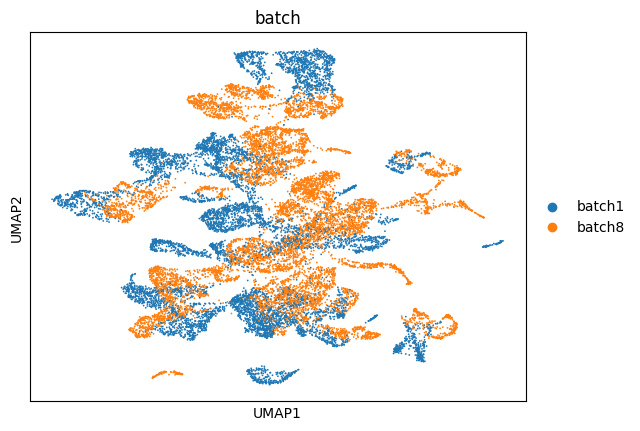

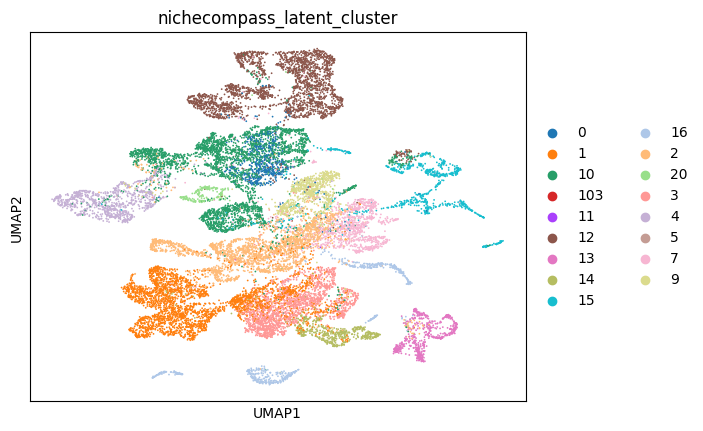

In [32]:
# Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb_layer_{layer}',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

os.makedirs(f'{folder_path}/figures', exist_ok=True)

labels = ['batch', 'nichecompass_latent_cluster'] # ['major_brain_region', 'Main_molecular_tissue_region']

# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


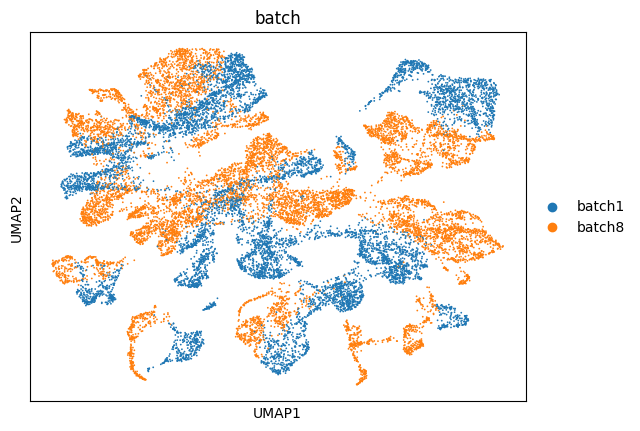

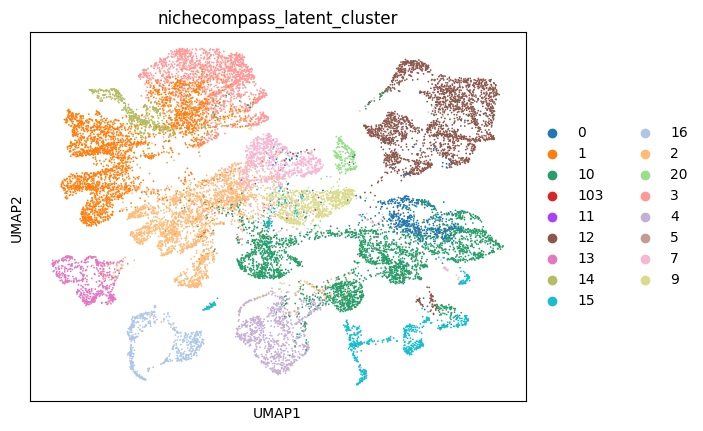

In [33]:
# Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb_layer_{layer}',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

os.makedirs(f'{folder_path}/figures', exist_ok=True)

labels = ['batch', 'nichecompass_latent_cluster'] # ['major_brain_region', 'Main_molecular_tissue_region']

# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


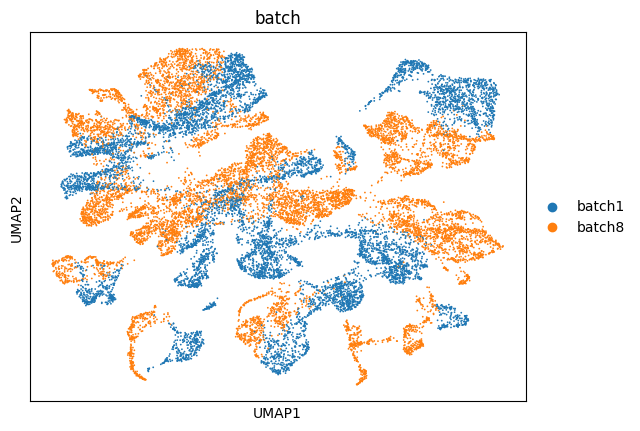

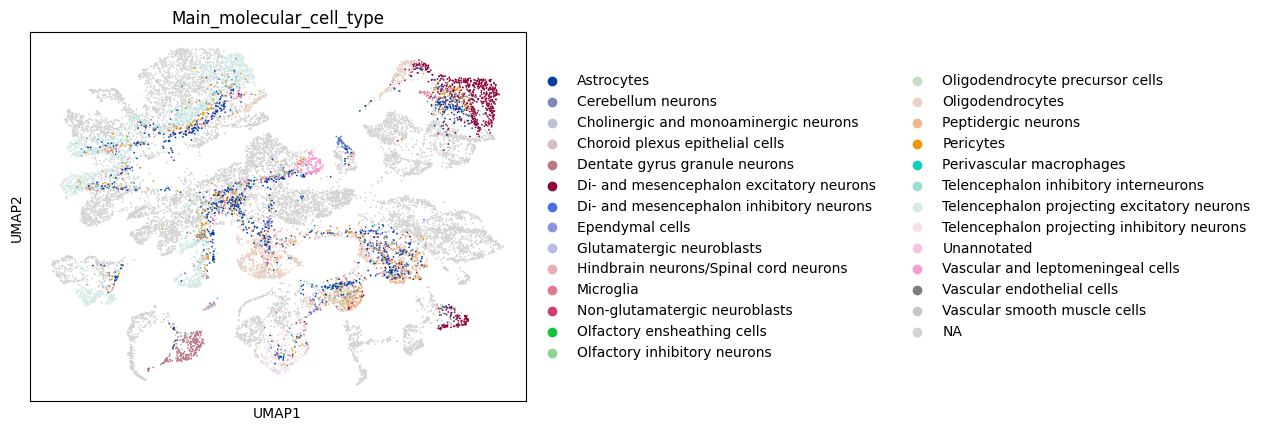

In [34]:
# Compute UMAP representation for (aggregated) cell gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb_layer_{layer}',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

os.makedirs(f'{folder_path}/figures', exist_ok=True)

labels = ['batch', 'Main_molecular_cell_type']

# Plot (aggregated) cell gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


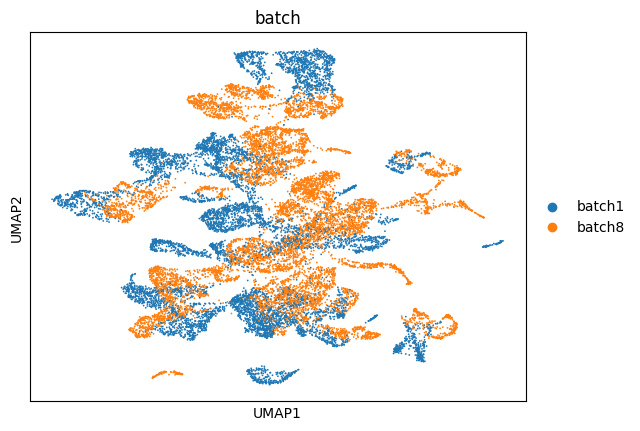

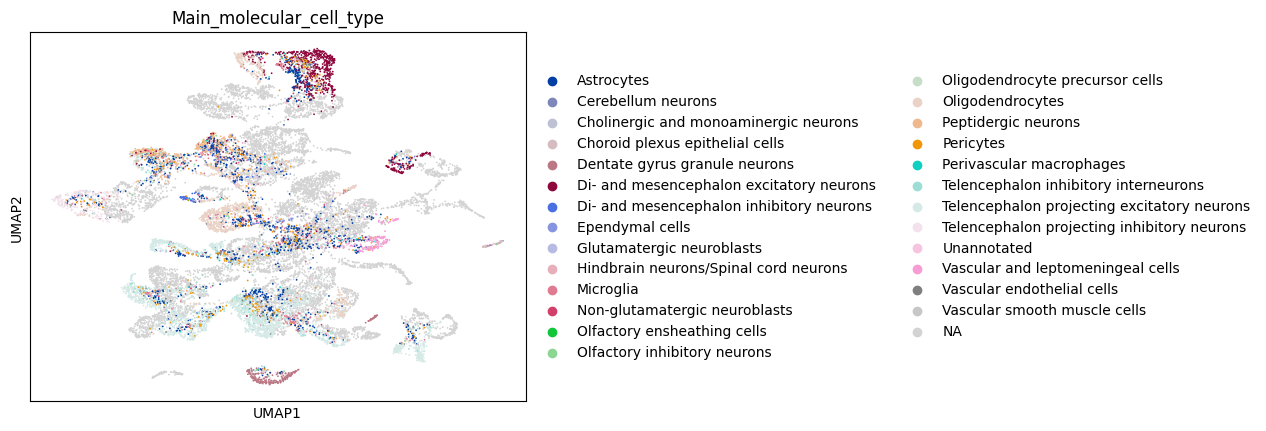

In [35]:
# Compute UMAP representation for (aggregated) cell gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb_layer_{layer}',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

os.makedirs(f'{folder_path}/figures', exist_ok=True)

labels = ['batch', 'Main_molecular_cell_type']

# Plot (aggregated) cell gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

## 3.3 Plot Embedding Similarity Stats

## 3.4 Compute Metrics

In [ ]:
os.makedirs(f'{folder_path}/metrics', exist_ok=True)

labels = ['cell_types', 'major_brain_region']

# NMI & ARI for label cols (neighborhood embedding)
for label in labels:
    cell_type_metrics = clustering_metrics(
        adata,
        emb_key=f'neighborhood_emb_layer_{layer}',
        label_col=label)
    
    metrics_df = pd.DataFrame([cell_type_metrics])
    metrics_df.to_csv(f'{folder_path}/metrics/{label}_metrics{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.csv', index=False)

## 3.5 Plot Loss Curve

In [ ]:
df = pd.read_csv(f'{folder_path}/jepa_r0.csv')
df['loss'] = pd.to_numeric(df['loss'], errors='coerce')

plt.figure(figsize=(10, 6))
plt.plot(df.index,df['loss'])
plt.title('Loss Function Over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.grid(True)
plt.show()